# Step 3: cut the movement

Each trial of step 2 still contains waiting before and after the movement. Here we find when the wrist really starts and stops moving, from its speed, and keep only that part.

Input: `kinematics.parquet` from `02_movement_table.ipynb` (not changed). Code: `cut.py`.

In [1]:
%load_ext autoreload
%autoreload 2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import cut
from config import OLD_PROCESSED_ROOT, PROCESSED_ROOT

## Settings
Change a value, then re-run from here. They are saved next to the output (`cut_settings.json`).

In [2]:
SPEED_THRESHOLD = 0.10   # the movement starts when the wrist speed passes this fraction of the
                         # trial's highest wrist speed (0.10 = 10%)
MIN_FRAMES_ABOVE = 3     # the speed must stay above the threshold this many frames in a row
                         # (so that camera jitter does not count as a start)
MARGIN_FRAMES = 0        # extra frames kept before the start and after the end (0 = cut exactly)
MIN_PEAK_SPEED = 0.15    # m/s: a trial whose highest wrist speed is below this has no real movement
                         # (only camera jitter) and is removed

In [3]:
# The settings collected for the functions.
settings = {"speed_threshold": SPEED_THRESHOLD, "min_frames_above": MIN_FRAMES_ABOVE,
            "margin_frames": MARGIN_FRAMES, "min_peak_speed": MIN_PEAK_SPEED}

kinematics = cut.load_kinematics()
trials = pd.read_parquet(PROCESSED_ROOT / "trials.parquet", columns=["trial_id", "task_id", "task_name"])
print(f"{kinematics['trial_id'].nunique()} trials, {len(kinematics):,} frames")

2788 trials, 418,526 frames


## Cut every trial

For each trial:
1. **Wrist speed** = distance moved per second, from the filtered wrist position.
2. **Start** = first moment the speed is above `SPEED_THRESHOLD` × the trial's highest speed, and stays above for `MIN_FRAMES_ABOVE` frames in a row (a single jump of the camera is not a start).
3. **End** = the same rule, read from the end of the trial backwards.
4. **Cut:** keep the frames from start to end (± `MARGIN_FRAMES`). `time_from_start_s` = 0 at the movement start.
5. `start_delay_s` = time from "person in start position" to the movement start (like a reaction time). `movement_duration_s` = end − start.

Same rule for every task. **Trials with no clear movement are removed**: highest speed below `MIN_PEAK_SPEED`, no stretch above the threshold, or no usable wrist data.

In [4]:
movement_cut, cut_trials, removed = cut.cut_movements(kinematics, settings)

print(f"Kept: {len(cut_trials)}, removed: {len(removed)}")
print(f"Frames: {len(movement_cut):,} kept of {len(kinematics):,}")
print(removed["reason"].value_counts().to_string())

Kept: 2764, removed: 24
Frames: 397,427 kept of 418,526
reason
peak speed too low                23
no stretch above the threshold     1


In [5]:
# Kept and removed trials per task.
status = pd.concat([cut_trials[["trial_id"]].assign(status="kept"), removed[["trial_id"]].assign(status="removed")])
status = status.merge(trials, on="trial_id")
pd.crosstab([status["task_id"], status["task_name"]], status["status"], margins=True)

,status,kept,removed,All
task_id,task_name,,,
1,Shoulder flexion with elbow extended,304,1,305
2,Shoulder abduction with elbow extended,278,0,278
3,Draw a 5 segment trajectory,216,0,216
4,Reaching different targets,528,16,544
5,Draw a circle,214,0,214
6,Horizontal reaching,720,1,721
7,Drinking test: reaching glass to mouth,261,6,267
8,Index to nose,243,0,243
All,,2764,24,2788


In [6]:
# A few removed trials, with the reason.
removed.merge(trials, on="trial_id").head(10)

,trial_id,reason,task_id,task_name
0,upper_limb_20260629_104733_099,peak speed too low,4,Reaching different targets
1,upper_limb_20260629_104733_100,peak speed too low,4,Reaching different targets
2,upper_limb_20260629_104733_101,peak speed too low,4,Reaching different targets
3,upper_limb_20260629_104733_102,peak speed too low,4,Reaching different targets
4,upper_limb_20260629_104733_103,peak speed too low,4,Reaching different targets
5,upper_limb_20260629_104733_104,peak speed too low,4,Reaching different targets
6,upper_limb_20260629_104733_105,peak speed too low,4,Reaching different targets
7,upper_limb_20260629_104733_106,peak speed too low,4,Reaching different targets
8,upper_limb_20260629_104733_107,peak speed too low,4,Reaching different targets
9,upper_limb_20260629_104733_108,peak speed too low,4,Reaching different targets


## Check: one trial
Left: wrist speed with the threshold line. Right: wrist height. Green = start, red = end. Choose any kept `trial_id`.

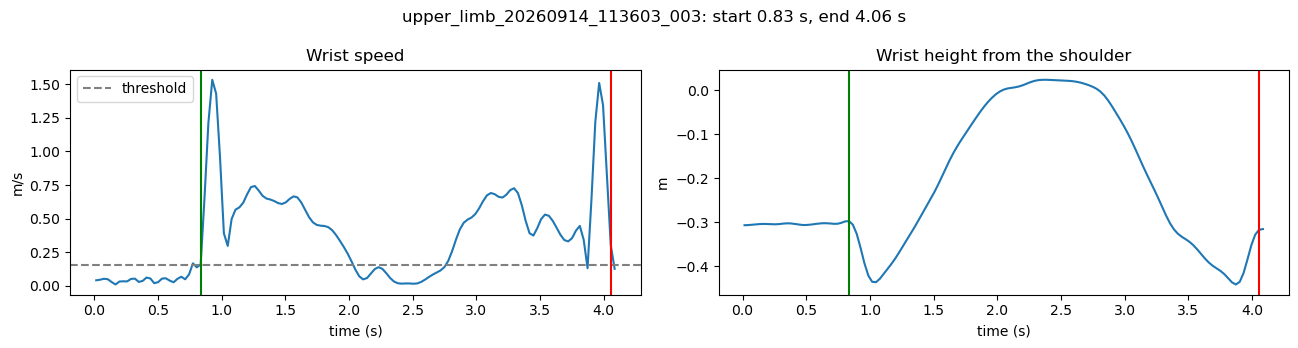

In [7]:
CHECK_TRIAL = "upper_limb_20260914_113603_003"   # task 1 (arm raised forward), repetition 3

one = kinematics[kinematics["trial_id"] == CHECK_TRIAL]
speed = cut.wrist_speed(one)
bounds = cut_trials.set_index("trial_id").loc[CHECK_TRIAL]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))

axes[0].plot(one["time_s"], speed)
axes[0].axhline(SPEED_THRESHOLD * np.nanmax(speed), color="grey", linestyle="--", label="threshold")
axes[0].set(title="Wrist speed", xlabel="time (s)", ylabel="m/s")
axes[0].legend()

axes[1].plot(one["time_s"], one["wrist_up"])
axes[1].set(title="Wrist height from the shoulder", xlabel="time (s)", ylabel="m")

for ax in axes:
    ax.axvline(bounds["start_s"], color="green")
    ax.axvline(bounds["end_s"], color="red")
fig.suptitle(f"{CHECK_TRIAL}: start {bounds['start_s']:.2f} s, end {bounds['end_s']:.2f} s")
plt.tight_layout()

## Check: movement duration per task (seconds)

In [8]:
(cut_trials.merge(trials, on="trial_id")
 .groupby(["task_id", "task_name"])["movement_duration_s"]
 .agg(trials="size", median="median", min="min", max="max")
 .round(2))

,,trials,median,min,max
task_id,task_name,,,,
1,Shoulder flexion with elbow extended,304,3.22,0.45,27.07
2,Shoulder abduction with elbow extended,278,2.76,0.54,37.05
3,Draw a 5 segment trajectory,216,14.27,0.92,391.94
4,Reaching different targets,528,2.78,0.14,18.13
5,Draw a circle,214,14.01,0.51,33.13
6,Horizontal reaching,720,2.70,0.43,48.05
7,Drinking test: reaching glass to mouth,261,5.92,0.91,298.69
8,Index to nose,243,2.09,0.09,45.30


## Comparison with the old code

The old table (`shape_tables.parquet` of the old repo) has `start_delay_s` and `movement_duration_s` per trial. Below: per task, the medians old and new and the median difference (new − old), for the trials in both tables.

They will not be identical: the old code cut by position, the new one by speed. Two other differences:
- **Duration, tasks 1, 2, 4, 6, 7, 8:** the old code kept **only the way out** (start → furthest point), the new one keeps the whole movement (out and back). New durations will be about 2× longer. Only tasks 3 and 5 are comparable.
- **Start delay, same 6 tasks:** the old code also skipped the end of the previous trial's return at the start. The new one does not, so in many trials (mostly before 02/09) the new start is at ~0 s: the arm is still coming down from the previous trial.

The old table only has trials that passed the checks, without repetition 1.

In [9]:
old = pd.read_parquet(OLD_PROCESSED_ROOT / "shape_tables.parquet", columns=["trial_id", "start_delay_s", "movement_duration_s"])
both = cut_trials.merge(old, on="trial_id", suffixes=("_new", "_old")).merge(trials, on="trial_id")
both["start_delay_diff"] = both["start_delay_s_new"] - both["start_delay_s_old"]
both["duration_diff"] = both["movement_duration_s_new"] - both["movement_duration_s_old"]

(both.groupby(["task_id", "task_name"])
 .agg(trials=("trial_id", "size"),
      start_delay_old=("start_delay_s_old", "median"), start_delay_new=("start_delay_s_new", "median"),
      start_delay_diff=("start_delay_diff", "median"),
      duration_old=("movement_duration_s_old", "median"), duration_new=("movement_duration_s_new", "median"),
      duration_diff=("duration_diff", "median"))
 .round(2))

,,trials,start_delay_old,start_delay_new,start_delay_diff,duration_old,duration_new,duration_diff
task_id,task_name,,,,,,,
1,Shoulder flexion with elbow extended,276,0.60,0.05,-0.43,1.40,3.14,1.58
2,Shoulder abduction with elbow extended,248,0.50,0.04,-0.36,1.24,2.70,1.38
3,Draw a 5 segment trajectory,186,0.13,0.03,-0.10,13.68,13.82,0.17
4,Reaching different targets,505,0.50,0.03,-0.40,1.33,2.75,1.35
5,Draw a circle,184,0.15,0.03,-0.10,13.44,13.74,0.19
6,Horizontal reaching,682,0.60,0.36,-0.20,1.10,2.67,1.47
7,Drinking test: reaching glass to mouth,226,1.74,0.42,-1.23,1.50,5.84,4.26
8,Index to nose,218,0.46,0.07,-0.19,0.98,2.05,1.05


In [11]:
movement_cut.head()

,trial_id,time_s,elbow_forward,elbow_out,elbow_up,wrist_forward,wrist_out,wrist_up,raw_elbow_forward,raw_elbow_out,raw_elbow_up,raw_wrist_forward,raw_wrist_out,raw_wrist_up,elbow_angle_deg,arm_elevation_deg,wrist_speed,elbow_angle_speed,arm_elevation_speed,time_from_start_s
0,upper_limb_20260629_090253_001,0.585896,0.017848,0.096181,-0.252710,0.090876,0.122818,-0.477278,0.017859,0.096223,-0.253078,0.087054,0.124739,-0.481629,160.269021,21.161256,0.266109,-13.429392,-7.910395,0.000000
1,upper_limb_20260629_090253_001,0.639163,0.024553,0.091585,-0.253772,0.104598,0.112095,-0.466986,0.024332,0.091471,-0.253698,0.105741,0.112679,-0.465031,159.308641,20.487641,0.386269,4.748252,-9.258857,0.053267
2,upper_limb_20260629_090253_001,0.692430,0.038244,0.085945,-0.256020,0.124458,0.106325,-0.460141,0.037588,0.086520,-0.255683,0.126386,0.103919,-0.458523,160.774872,20.174873,0.447680,45.153365,11.279503,0.106534
3,upper_limb_20260629_090253_001,0.745697,0.057168,0.084003,-0.255474,0.150673,0.113454,-0.454742,0.058763,0.083281,-0.255561,0.149002,0.114215,-0.456346,164.119010,21.689292,0.702225,35.625240,52.345078,0.159801
4,upper_limb_20260629_090253_001,0.798964,0.080502,0.087874,-0.247058,0.192935,0.124242,-0.435923,0.079218,0.088097,-0.247986,0.192283,0.125679,-0.437527,164.570171,25.751404,1.161528,-30.567080,101.465346,0.213068


## Save
Writes `movement_cut.parquet` (the cut frames of the kept trials), `movement_cut_trials.parquet` (one row per kept trial) and `cut_settings.json` (the settings above) to `data/processed/`. `kinematics.parquet` is not changed.

In [10]:
cut.save_cut(movement_cut, cut_trials, settings)

movement_cut.parquet              63.4 MB
movement_cut_trials.parquet        0.1 MB
cut_settings.json                  0.0 MB
